In [6]:
!pip install groq beautifulsoup4 requests pandas matplotlib seaborn


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: C:\Users\ANANYA\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [7]:
!pip install matplotlib


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: C:\Users\ANANYA\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [8]:
!pip install seaborn


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: C:\Users\ANANYA\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [ ]:
import json
import requests
from bs4 import BeautifulSoup
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from groq import Groq

# Initialize Groq Client
GROQ_API_KEY = "your_api_key" 
client = Groq(api_key=GROQ_API_KEY)

In [10]:
def scrape_reviews(url):
    print(f"Attempting to scrape: {url}")
    # Headers trick websites into thinking the request is coming from a normal browser
    headers = {
        "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36",
        "Accept-Language": "en-US, en;q=0.5"
    }
    
    try:
        response = requests.get(url, headers=headers, timeout=10)
        response.raise_for_status()
        soup = BeautifulSoup(response.content, "html.parser")
        
        reviews = []
        # A generic approach: extracting longer text blocks (likely to be reviews)
        for p in soup.find_all("p"):
            text = p.get_text(strip=True)
            if len(text) > 40: 
                reviews.append(text)
                
        # Limit to 15 reviews to keep API processing fast for testing
        return reviews[:15]
        
    except Exception as e:
        print(f"Scraping failed: {e}")
        return []

# Get the URL from the user
product_link = input("Enter the product link: ")
scraped_reviews = scrape_reviews(product_link)

# Fallback data if the website blocks the scraper
if not scraped_reviews:
    print("Scraping blocked or no reviews found. Loading sample reviews for demonstration...")
    scraped_reviews = [
        "The battery life on this is amazing! Lasts two whole days without charging.",
        "Terrible product. It broke within the first week of use and the plastic feels incredibly cheap.",
        "It's decent for the price, but the screen could be a bit brighter in sunlight.",
        "I love the design, very sleek and modern. Highly recommend to anyone looking for an upgrade!",
        "Customer service was completely unhelpful when I tried to return it due to a dent."
    ]

print(f"\nSuccessfully loaded {len(scraped_reviews)} reviews to analyze.")

Attempting to scrape: https://www.amazon.in/HP-Smartchoice-Victus-Upgradeable-Gamepass/dp/B0GWQ7MQ1Q/ref=sr_1_1?_encoding=UTF8&content-id=amzn1.sym.33b9912d-2d10-44c1-a831-9730b2c52948&dib=eyJ2IjoiMSJ9.Wxwhl-Seja3dLIPaF6d3f74YZBUVX1YB8GdY7oz_wtwAO1R-0DcLphpAQ8osrVHECQvtUJ_yYH9hVZySL_LiVId7wSoxFbcoW0xRLIN5cpTAELMwH_MdP2Ci6XxbeRCmLebcYfWM-mm1SH0fMUCoYOexfceq7VhttfwvdjYQ5Wf2RuAPp-dJy183DCPeN7K28UBUWdDQUFAneEVAcueM59DYR8WwH8bDMV7T89AcAsQ-XiiN_epv6UDI6GAzIgBDoYORxy3IUyMP3gQlzm09izDKbuME7_NHUOu-omJacfE.HCbCqXYd9RdzzXHEhg9TL7Slkox-glSfDt4uQnUwdAk&dib_tag=se&pd_rd_r=eade4152-bc30-4acf-b01e-7ce4fc1b4712&pd_rd_w=3ajHW&pd_rd_wg=d2VIy&qid=1792211820&sr=8-1&th=1

Successfully loaded 15 reviews to analyze.


In [18]:
def analyze_review_with_groq(review_text):
    prompt = f"""
    You are an expert product analyst. Read the following customer review and analyze its sentiment and key focus areas (e.g., battery, build quality, customer service).
    
    Review: "{review_text}"
    
    Return ONLY a valid JSON object in the exact following format, with no extra text or markdown formatting:
    {{
        "sentiment": "Positive" | "Negative" | "Neutral",
        "focus_areas": ["area1", "area2"]
    }}
    """
    
    try:
        chat_completion = client.chat.completions.create(
            messages=[
                {"role": "system", "content": "You output strictly valid JSON without any markdown tags."},
                {"role": "user", "content": prompt}
            ],
            model="openai/gpt-oss-120b", 
            
            temperature=0.0, # Temperature 0 ensures reliable, structured JSON formatting
            max_tokens=150
        )
        
        response_text = chat_completion.choices[0].message.content.strip()
        return json.loads(response_text)
    
    except Exception as e:
        print(f"Error parsing review: {e}")
        return {"sentiment": "Neutral", "focus_areas": ["Unknown"]}

print("Sending reviews to Groq API for analysis...")
analysis_results = []

for idx, review in enumerate(scraped_reviews):
    result = analyze_review_with_groq(review)
    result["review"] = review # Append original text to the data
    analysis_results.append(result)

# Load into a Pandas DataFrame for easy viewing
df = pd.DataFrame(analysis_results)
display(df.head())

Sending reviews to Groq API for analysis...
Error parsing review: Unterminated string starting at: line 2 column 18 (char 19)
Error parsing review: Expecting value: line 1 column 1 (char 0)
Error parsing review: Unterminated string starting at: line 3 column 5 (char 35)


,sentiment,focus_areas,review
0,Positive,[returns],This product has fewer returns than average co...
1,Positive,[ratings],86% positive ratings from 100K+ customers
2,Neutral,[Unknown],"HP Smartchoice Victus, AMD Ryzen 7 7445HS, 6GB..."
3,Positive,"[price, quantity, delivery, packaging]",Amazon always ahead to save your pocket they g...
4,Neutral,[],We'll check if this review meets ourcommunity ...


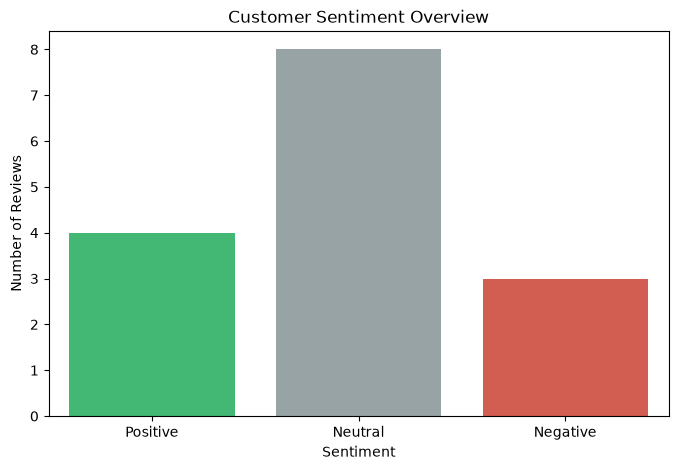

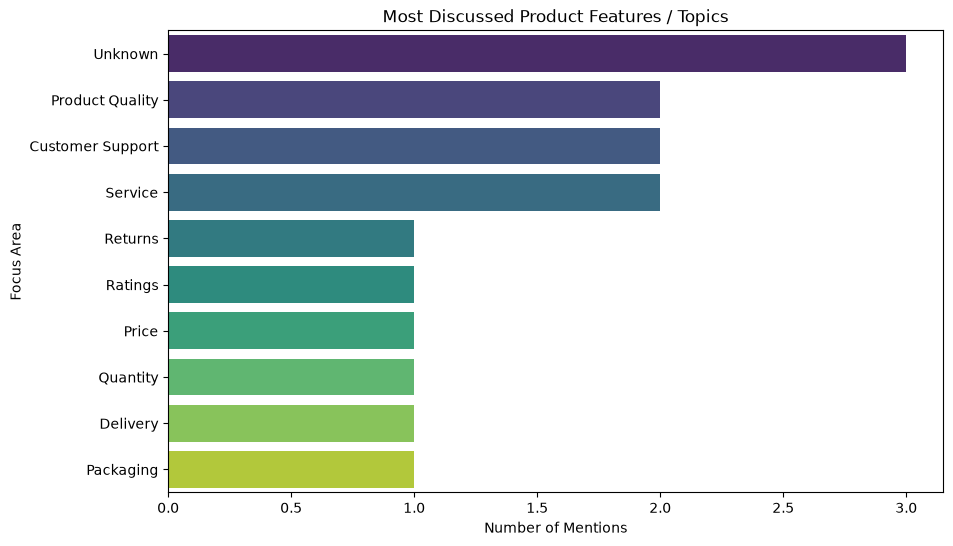

In [19]:
# 1. Plot Customer Sentiment Distribution
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df, 
    x='sentiment', 
    hue='sentiment', 
    palette={'Positive': '#2ecc71', 'Negative': '#e74c3c', 'Neutral': '#95a5a6'}, 
    legend=False
)
plt.title("Customer Sentiment Overview")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

# 2. Extract and Plot Top Focus Areas
all_focus_areas = []
for areas in df['focus_areas']:
    all_focus_areas.extend([area.title() for area in areas])

# Count frequency of each focus area
focus_area_counts = pd.Series(all_focus_areas).value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=focus_area_counts.values, 
    y=focus_area_counts.index, 
    hue=focus_area_counts.index, 
    palette='viridis', 
    legend=False
)
plt.title("Most Discussed Product Features / Topics")
plt.xlabel("Number of Mentions")
plt.ylabel("Focus Area")
plt.show()

In [20]:
print("--- ACTIONABLE PRODUCT INSIGHTS ---")
pos_count = len(df[df['sentiment'] == 'Positive'])
neg_count = len(df[df['sentiment'] == 'Negative'])

print(f"Total Analyzed: {len(df)}")
print(f"Overall Consensus: {'Generally Positive' if pos_count > neg_count else 'Needs Attention'}")

print("\n⚠️ Key Areas Driving Negative Feedback:")
negative_reviews = df[df['sentiment'] == 'Negative']

if not negative_reviews.empty:
    neg_areas = []
    for areas in negative_reviews['focus_areas']:
        neg_areas.extend([a.title() for a in areas])
        
    top_complaints = pd.Series(neg_areas).value_counts().head(5)
    for area, count in top_complaints.items():
        print(f" - {area}: mentioned {count} time(s)")
else:
    print(" - No major negative trends identified in this batch!")

--- ACTIONABLE PRODUCT INSIGHTS ---
Total Analyzed: 15
Overall Consensus: Generally Positive

⚠️ Key Areas Driving Negative Feedback:
 - Product Quality: mentioned 2 time(s)
 - Customer Support: mentioned 2 time(s)
 - Service: mentioned 2 time(s)
 - Charging: mentioned 1 time(s)
 - Screen: mentioned 1 time(s)
